In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
df=pd.read_csv("Food_Delivery_Times.csv")

In [21]:
df

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


In [22]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [23]:
df.dtypes

Order_ID                    int64
Distance_km               float64
Weather                    object
Traffic_Level              object
Time_of_Day                object
Vehicle_Type               object
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

In [24]:
df.shape

(1000, 9)

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [26]:
df.isnull().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [27]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [28]:
df['Traffic_Level'].unique()

array(['Low', 'Medium', 'High', nan], dtype=object)

In [29]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

# Duplicate values

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.isnull().sum()/len(df)*100

Order_ID                  0.0
Distance_km               0.0
Weather                   3.0
Traffic_Level             3.0
Time_of_Day               3.0
Vehicle_Type              0.0
Preparation_Time_min      0.0
Courier_Experience_yrs    3.0
Delivery_Time_min         0.0
dtype: float64

**Filling Missing values**

**AS the missing value  % is < than 5% We will fill the data with fillna()**

### Handling missing values 

**Here Weather, Traffic _level, Time _of _day all these are categorical columns so we use here MODE to fill**

In [32]:
df['Weather'].isnull().sum()

np.int64(30)

In [33]:
df['Weather'].mode()

0    Clear
Name: Weather, dtype: object

In [34]:
df['Weather'].unique()

array(['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy', nan], dtype=object)

In [35]:
df['Weather'] = df['Weather'].fillna(df['Weather'].mode()[0])

In [36]:
df['Traffic_Level'].isnull().sum()

np.int64(30)

In [37]:
df['Traffic_Level'] = df['Traffic_Level'].fillna(df['Traffic_Level'].mode()[0])

In [38]:
df['Time_of_Day'] = df['Time_of_Day'].fillna(df['Time_of_Day'].mode()[0])

**For numerical columns**

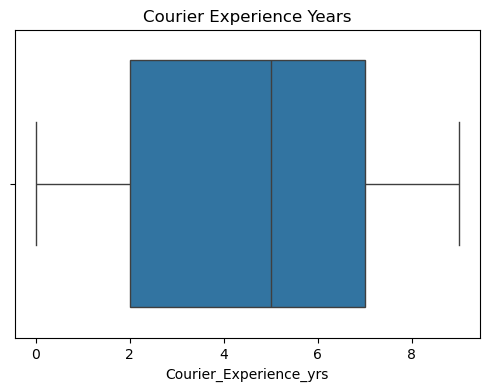

In [39]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Courier_Experience_yrs'])
plt.title("Courier Experience Years")
plt.show()

**As there are no outliers exist** 
- we use mean to fill

In [40]:
df['Courier_Experience_yrs']=df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].mean())

**Checking the NULL_VALUES**

In [41]:
df.isnull().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

There are no null values

In [42]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [43]:
df['Delivery_speed']=round(df['Distance_km']/df['Delivery_Time_min'],2)*10

In [44]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Delivery_speed
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43,1.8
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84,2.0
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59,1.6
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37,2.0
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68,2.8


# Distance vs Delivery Time

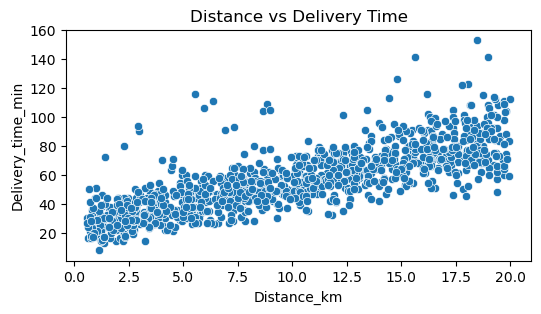

In [45]:
plt.figure(figsize=(6,3))
sns.scatterplot(x='Distance_km',y='Delivery_Time_min',data=df)
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance_km")
plt.ylabel("Delivery_time_min")
plt.show()

**Delivery time increases as delivery distance increases. The scatter plot shows a clear positive relationship between distance and delivery time, indicating that distance is a major factor affecting delivery duration.**

# Traffic Level vs Delivery Time

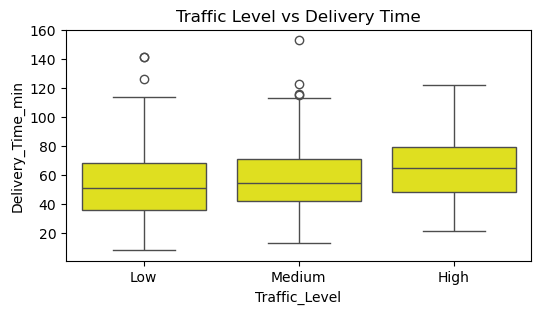

In [46]:
plt.figure(figsize=(6,3))
sns.boxplot(x='Traffic_Level',y='Delivery_Time_min',data=df,color='yellow')
plt.title('Traffic Level vs Delivery Time')
plt.show()
           

**Traffic conditions significantly affect delivery time. Deliveries during high traffic periods have the highest median delivery time and greater variability compared to low and medium traffic conditions.**

# Courier Experience vs Delivery Time

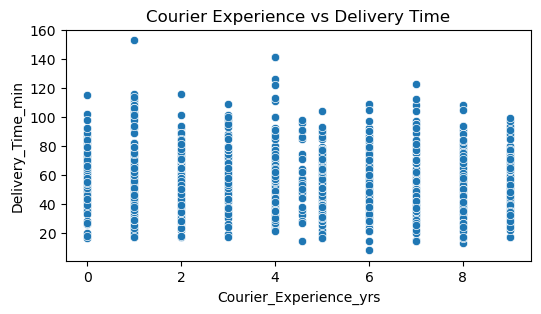

In [47]:
plt.figure(figsize=(6,3))
sns.scatterplot(x='Courier_Experience_yrs',
                y='Delivery_Time_min',
                data=df)

plt.title("Courier Experience vs Delivery Time")
plt.show()

**Courier experience does not show a strong relationship with delivery time. Delivery duration appears to be influenced more by operational factors such as distance and traffic rather than courier experience.**

# Weather vs Delivery Time

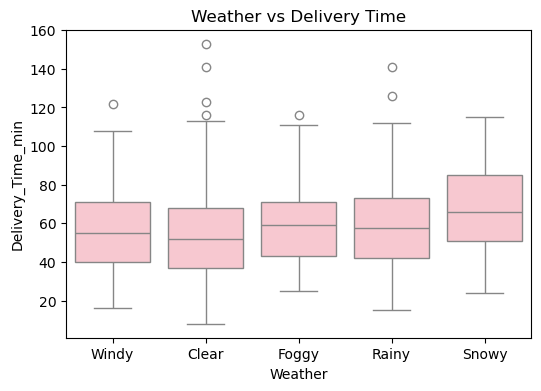

In [48]:

plt.figure(figsize=(6,4))
sns.boxplot(x='Weather', y='Delivery_Time_min', data=df,color='pink')

plt.title("Weather vs Delivery Time")
plt.show()

**Delivery time varies slightly based on weather conditions. Orders during snowy and foggy weather tend to have higher median delivery times, indicating slower deliveries, while clear and windy conditions generally show slightly faster delivery times. This suggests that adverse weather conditions can negatively impact delivery efficiency.**

# Time of Day vs Delivery Time

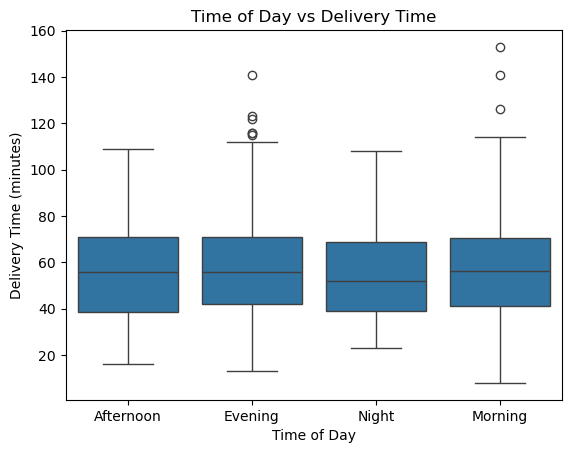

In [49]:
sns.boxplot(x='Time_of_Day', y='Delivery_Time_min', data=df)

plt.title("Time of Day vs Delivery Time")
plt.xlabel("Time of Day")
plt.ylabel("Delivery Time (minutes)")
plt.show()

**Delivery times remain largely consistent across all times of the day, with median delivery times around 50–55 minutes. However, night deliveries tend to be slightly faster and more consistent, while morning and evening periods show greater variability and several extreme delays (outliers), likely due to higher demand or traffic conditions.**

# Traffic Level vs Delivery Speed

In [50]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min', 'Delivery_speed'],
      dtype='object')

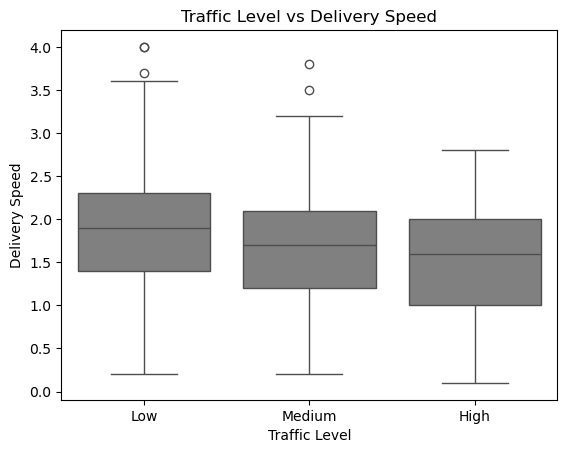

In [51]:
sns.boxplot(x='Traffic_Level', y='Delivery_speed', data=df,color='grey')

plt.title("Traffic Level vs Delivery Speed")
plt.xlabel("Traffic Level")
plt.ylabel("Delivery Speed")
plt.show()

**Delivery speed decreases as traffic level increases. Orders in low traffic conditions show the highest median delivery speed, while high traffic conditions have the lowest delivery speed, indicating that traffic congestion negatively impacts delivery efficiency.**

# Preparation Time vs Delivery Time

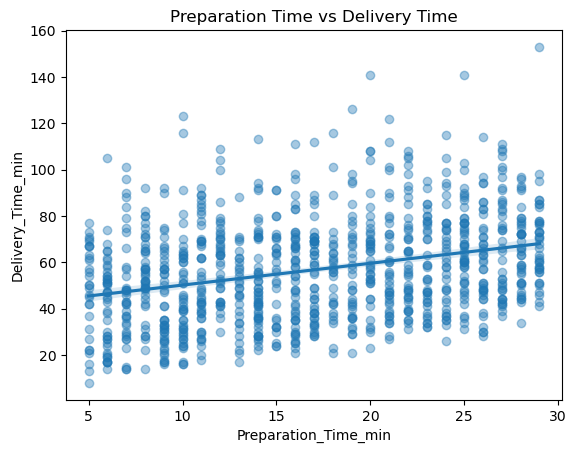

In [52]:
sns.regplot(
    x='Preparation_Time_min',
    y='Delivery_Time_min',
    data=df,
    scatter_kws={'alpha':0.4}
)

plt.title("Preparation Time vs Delivery Time")
plt.show()

**The plot shows a slight positive relationship between preparation time and delivery time, meaning that as food preparation time increases, delivery time also tends to increase, although the relationship is not very strong due to the wide spread of data points.**

# Correlation Analysis

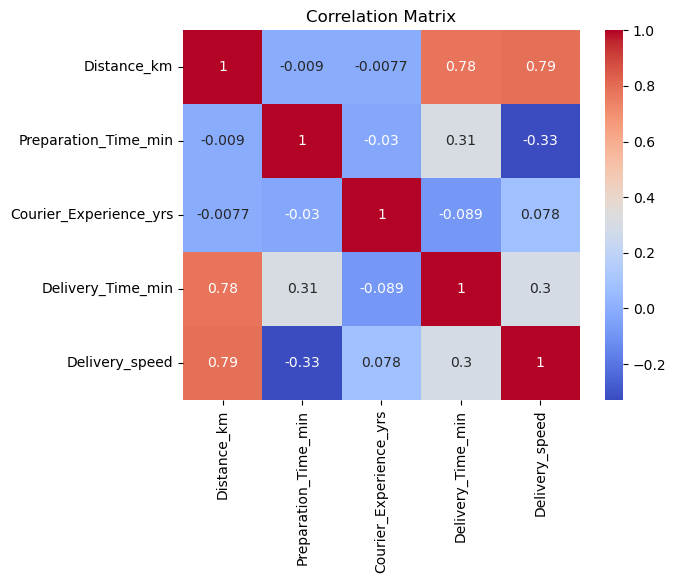

In [53]:
corr = df[['Distance_km',
           'Preparation_Time_min',
           'Courier_Experience_yrs',
           'Delivery_Time_min',
           'Delivery_speed']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

**Distance is the strongest factor**: Longer distances significantly increase delivery time and speed.
- **Preparation time is a bottleneck**: More preparation delays deliveries and reduces speed.
- **Courier experience has minimal effect**: Experience shows weak influence compared to operational factors.
- **Delivery speed helps moderately**: Faster speed reduces delivery time, but distance dominates overall.
- **Conclusion**: Optimizing distance and preparation time will have the greatest impact on improving delivery efficiency.

In [54]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Delivery_speed
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43,1.8
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84,2.0
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59,1.6
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37,2.0
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68,2.8


- # Overall Average Delivery Time

In [55]:
round(df['Delivery_Time_min'].mean(),2)

np.float64(56.73)

**The average delivery time across all orders is 56.73 minutes.**

- ## Average Delivery Time by Traffic



In [56]:
df.groupby('Traffic_Level')['Delivery_Time_min'].mean().round(2)

Traffic_Level
High      64.81
Low       52.89
Medium    56.45
Name: Delivery_Time_min, dtype: float64

**Deliveries during high traffic took significantly longer than during low traffic.**

- ## Average Delivery Time by Weather

In [57]:
df.groupby('Weather')['Delivery_Time_min'].mean().round(2)

Weather
Clear    53.15
Foggy    59.47
Rainy    59.79
Snowy    67.11
Windy    55.46
Name: Delivery_Time_min, dtype: float64

- ## Average Delivery Time by Time of Day

In [58]:
df.groupby('Time_of_Day')['Delivery_Time_min'].mean().round(2)

Time_of_Day
Afternoon    56.08
Evening      57.48
Morning      57.01
Night        55.21
Name: Delivery_Time_min, dtype: float64

**Evening and Morning deliveries tend to take longer due to higher traffic.**

## Maximum and Minimum Delivery Time

In [59]:
df['Delivery_Time_min'].max()

153

In [60]:
df['Delivery_Time_min'].min()

8

In [61]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min', 'Delivery_speed'],
      dtype='object')

# Pivot Analysis

## Traffic Level × Time of Day

In [62]:
pivot1=round(df.pivot_table(index='Traffic_Level',columns='Time_of_Day',values='Delivery_Time_min',aggfunc='mean'),2)

In [63]:
pivot1

Time_of_Day,Afternoon,Evening,Morning,Night
Traffic_Level,,,,
High,64.22,64.58,65.23,65.83
Low,51.02,54.19,53.41,53.33
Medium,57.30,57.23,56.44,51.70


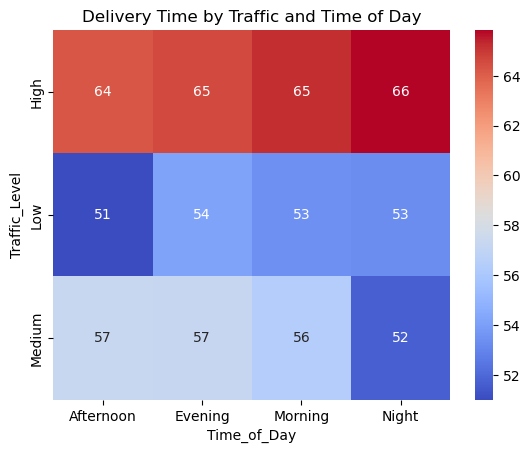

In [64]:
sns.heatmap(pivot1, annot=True, cmap='coolwarm')
plt.title("Delivery Time by Traffic and Time of Day")
plt.show()

**Delivery delays are more frequent during evening and night periods, likely due to increased order demand and traffic congestion during peak hours.**

## Weather × Traffic Impact

In [65]:
pivot2=round(df.pivot_table(index='Traffic_Level',columns='Weather',values='Delivery_Time_min',aggfunc='mean'),2)
pivot2

Weather,Clear,Foggy,Rainy,Snowy,Windy
Traffic_Level,,,,,
High,57.16,67.24,77.05,70.90,63.48
Low,49.91,53.34,55.04,61.93,51.38
Medium,54.24,63.03,55.06,71.73,53.79


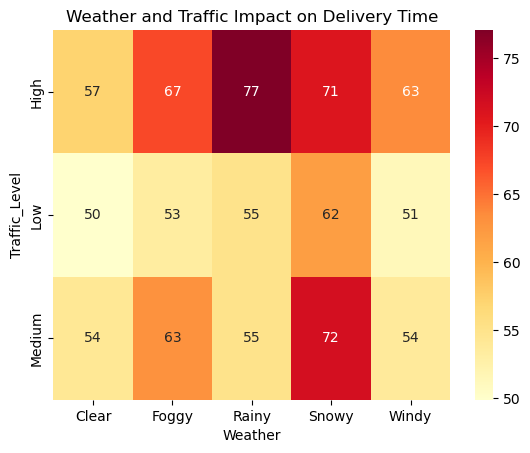

In [66]:
sns.heatmap(pivot2, annot=True, cmap='YlOrRd')
plt.title("Weather and Traffic Impact on Delivery Time")
plt.show()

**Rainy weather combined with high traffic results in the longest delivery times, indicating that adverse weather conditions significantly slow down delivery operations when traffic congestion is also present.**

In [67]:
## Total Orders
total_orders = df.shape[0]
total_orders

1000

In [68]:
## Average Delivery Time
avg_delivery_time = df['Delivery_Time_min'].mean()
round(avg_delivery_time,2)

np.float64(56.73)

In [70]:
## Average Delivery Speed
avg_speed = df['Delivery_speed'].mean()
round(avg_speed,3)

np.float64(1.692)

In [71]:
## slowest Delivery
df['Delivery_Time_min'].max()

153

In [72]:
## Fastest Delivery
df['Delivery_Time_min'].min()

8

## Delayed vs On-Time deliveries.

In [73]:
df['Delivery_Status'] = df['Delivery_Time_min'].apply(
    lambda x: 'Delayed' if x > 60 else 'On-Time'
)

In [74]:
df['Delivery_Status'].value_counts()

Delivery_Status
On-Time    585
Delayed    415
Name: count, dtype: int64

In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 1000 non-null   object 
 3   Traffic_Level           1000 non-null   object 
 4   Time_of_Day             1000 non-null   object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  1000 non-null   float64
 8   Delivery_Time_min       1000 non-null   int64  
 9   Delivery_speed          1000 non-null   float64
 10  Delivery_Status         1000 non-null   object 
dtypes: float64(3), int64(3), object(5)
memory usage: 86.1+ KB


In [77]:
df.to_csv("food_delivery_cleaned.csv", index=False)

In [78]:
import os
os.getcwd()

'C:\\Users\\VARSH'

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 1000 non-null   object 
 3   Traffic_Level           1000 non-null   object 
 4   Time_of_Day             1000 non-null   object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  1000 non-null   float64
 8   Delivery_Time_min       1000 non-null   int64  
 9   Delivery_speed          1000 non-null   float64
 10  Delivery_Status         1000 non-null   object 
dtypes: float64(3), int64(3), object(5)
memory usage: 86.1+ KB
